<a href="https://colab.research.google.com/github/guruhbagus73/KlasifikasiWINE/blob/main/KlasifikasiWINE_Guruh_Bagus_Prakoso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# KLASIFIKASI KUALITAS ANGGUR (WINE QUALITY) DENGAN MACHINE LEARNING

**Nama :** Guruh Bagus Prakoso  
**NIM :** 2404010029  


## 1. Persiapan Data
Mengimpor library, memuat dataset training, testing, dan template file hasil prediksi.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 29
train = pd.read_csv(U+'data_train_BP.csv')
test  = pd.read_csv(U+'data_test_BP.csv')
templ = pd.read_csv(U+'hasilprediksi_3digitNIMterakhir_BP.csv', sep=';')
print('Data training :', train.shape)
print('Data testing  :', test.shape)
print('Template hasil:', templ.shape, '-> kolom:', list(templ.columns))
train.head()

Data training : (857, 13)
Data testing  : (286, 12)
Template hasil: (286, 2) -> kolom: ['Id', 'Quality']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


**Interpretasi:** Data training berisi 857 sampel dengan 11 fitur kimiawi, kolom `quality` (target), dan `Id`. Data testing berisi 286 sampel dengan fitur yang sama tanpa `quality`. Template hasil hanya berisi `Id` dan `Quality` (dipisah titik koma `;`) sehingga format keluaran harus mengikutinya.

In [ ]:
print(train.dtypes)
print('\nKolom train yang tidak ada di test:', set(train.columns)-set(test.columns))
print('Id test sama dengan Id template:', set(test.Id)==set(templ.Id))
print('\nDistribusi quality (training):')
print(train.quality.value_counts().sort_index())

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64
dtype: object

Kolom train yang tidak ada di test: {'quality'}
Id test sama dengan Id template: True

Distribusi quality (training):
quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64


**Interpretasi:** Seluruh fitur bertipe numerik. Satu-satunya perbedaan kolom antara train dan test adalah `quality`, sesuai soal. Distribusi kelas **tidak seimbang**: kelas 5 dan 6 mendominasi, sedangkan kelas 3, 4, dan 8 sangat sedikit. Hal ini membuat akurasi sulit tinggi dan kelas minoritas sulit diprediksi.

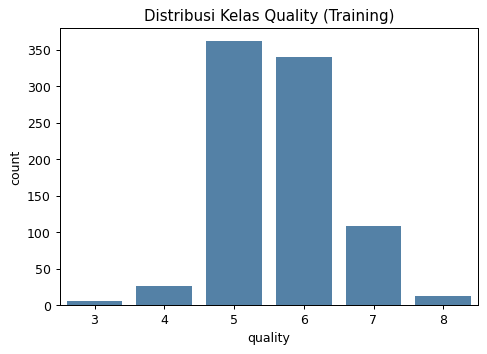

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='quality', data=train, color='steelblue')
plt.title('Distribusi Kelas Quality (Training)'); plt.show()

## 2. Pembersihan Data
Memeriksa missing values, duplikasi, dan kebutuhan penskalaan fitur.

In [ ]:
print('Missing values training:', train.isna().sum().sum())
print('Missing values testing  :', test.isna().sum().sum())
print('Baris duplikat (training):', train.drop(columns='Id').duplicated().sum())
print('Id duplikat (training)   :', train.Id.duplicated().sum())

Missing values training: 0
Missing values testing  : 0
Baris duplikat (training): 76
Id duplikat (training)   : 0


**Interpretasi:** Tidak ditemukan nilai hilang pada training maupun testing, sehingga tidak perlu imputasi atau penghapusan baris. Terdapat 76 baris yang nilai fiturnya identik (bukan duplikat `Id`); baris ini dipertahankan karena dataset wine memang memuat sampel serupa dengan `Id` berbeda, dan tidak ada `Id` ganda. Kolom `Id` hanya pengenal, bukan fitur, jadi **tidak dipakai** untuk pelatihan agar model tidak belajar dari identitas baris.

In [ ]:
features = [c for c in train.columns if c not in ('quality','Id')]
desc = train[features].describe().T[['min','max','mean','std']]
desc['rentang'] = desc['max']-desc['min']
desc.round(4)

,min,max,mean,std,rentang
fixed acidity,4.6000,15.6000,8.2620,1.7020,11.0000
volatile acidity,0.1200,1.5800,0.5294,0.1792,1.4600
citric acid,0.0000,1.0000,0.2674,0.1951,1.0000
residual sugar,0.9000,15.5000,2.5062,1.2935,14.6000
chlorides,0.0120,0.6110,0.0868,0.0487,0.5990
free sulfur dioxide,1.0000,68.0000,15.7830,10.3004,67.0000
total sulfur dioxide,6.0000,278.0000,45.9784,31.6921,272.0000
density,0.9901,1.0032,0.9967,0.0019,0.0131
pH,2.7400,4.0100,3.3131,0.1521,1.2700
sulphates,0.3900,2.0000,0.6567,0.1674,1.6100


**Interpretasi (feature scaling):** Skala fitur sangat bervariasi. `total sulfur dioxide` berkisar 6–278, sedangkan `density` hanya 0,990–1,003 dan `chlorides` 0,012–0,611. Model berbasis jarak/gradien (Logistic Regression, SVM, jaringan saraf/Backpropagation) sensitif terhadap skala, sehingga **perlu standardisasi** (`StandardScaler`). Model berbasis pohon (Random Forest, Extra Trees) tidak membutuhkannya, tetapi tetap tidak dirugikan. Penskalaan dimasukkan ke dalam *pipeline* agar tidak terjadi kebocoran data.

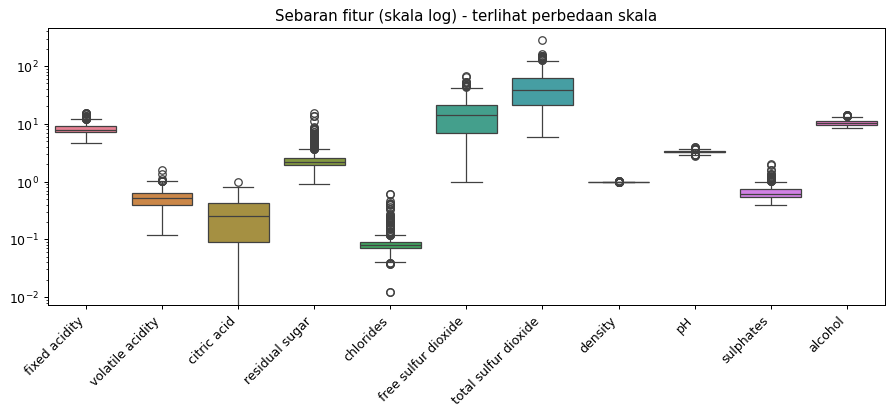

In [ ]:
fig, ax = plt.subplots(figsize=(12,4))
sns.boxplot(data=train[features], ax=ax); plt.xticks(rotation=45, ha='right')
ax.set_yscale('log'); ax.set_title('Sebaran fitur (skala log) - terlihat perbedaan skala'); plt.show()

volatile acidity       -0.430059
density                -0.207903
total sulfur dioxide   -0.172737
chlorides              -0.144946
free sulfur dioxide    -0.054509
pH                     -0.033199
residual sugar         -0.020511
fixed acidity           0.092714
citric acid             0.221263
sulphates               0.260703
alcohol                 0.473555
Name: quality, dtype: float64


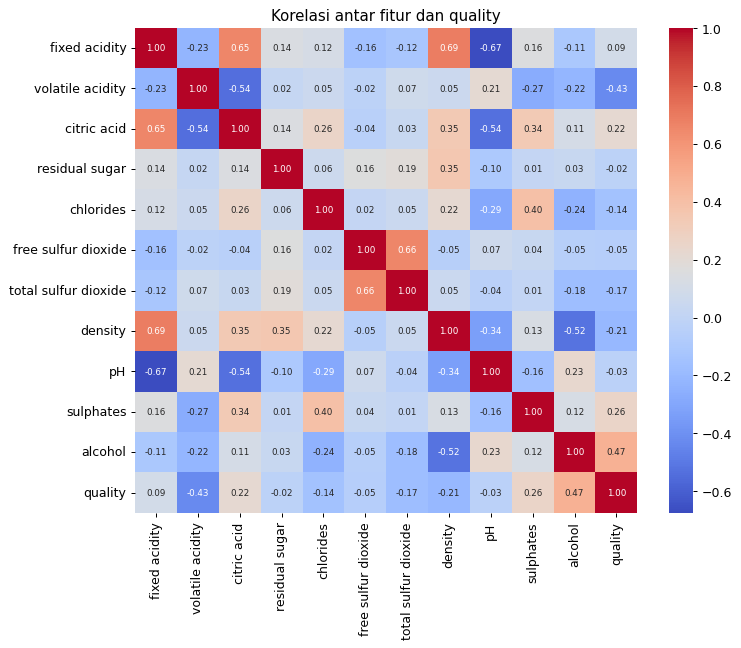

In [ ]:
plt.figure(figsize=(9,7))
sns.heatmap(train[features+['quality']].corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size':7})
plt.title('Korelasi antar fitur dan quality'); plt.show()
print(train[features+['quality']].corr()['quality'].drop('quality').sort_values())

**Interpretasi:** `alcohol` memiliki korelasi positif terkuat dengan `quality`, diikuti `sulphates` dan `citric acid`. `volatile acidity` berkorelasi negatif terkuat (kadar asam asetat tinggi menurunkan kualitas). Ini sejalan dengan pengetahuan domain winemaking.

## 3. Pembuatan Model
Membagi data (80% latih, 20% validasi, *stratified*), lalu membandingkan beberapa algoritma dengan *5-fold cross-validation*, termasuk jaringan saraf Backpropagation (`MLPClassifier`).

Latih: (685, 11) | Validasi: (172, 11)
Extra Trees              0.6511
Random Forest            0.6482
SVM (RBF)                0.6175
Gradient Boosting        0.6161
Logistic Regression      0.6029
MLP / Backpropagation    0.6029
dtype: float64


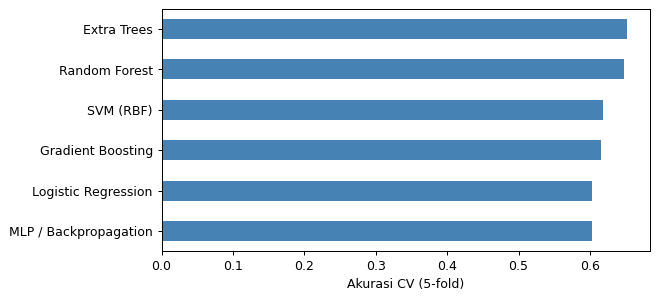

In [ ]:
X = train[features]; y = train['quality']
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Latih:', X_tr.shape, '| Validasi:', X_val.shape)

models = {
 'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
 'SVM (RBF)':           make_pipeline(StandardScaler(), SVC()),
 'MLP / Backpropagation': make_pipeline(StandardScaler(), MLPClassifier((64,32), max_iter=2000, random_state=SEED)),
 'Gradient Boosting':   GradientBoostingClassifier(random_state=SEED),
 'Random Forest':       RandomForestClassifier(n_estimators=500, random_state=SEED),
 'Extra Trees':         ExtraTreesClassifier(n_estimators=500, random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
hasil = {n: cross_val_score(m, X_tr, y_tr, cv=cv).mean() for n,m in models.items()}
hasil = pd.Series(hasil).sort_values(ascending=False)
print(hasil.round(4))
hasil.plot.barh(color='steelblue', figsize=(7,3.5)); plt.xlabel('Akurasi CV (5-fold)'); plt.gca().invert_yaxis(); plt.show()

**Interpretasi:** Model berbasis pohon (Extra Trees dan Random Forest) unggul dibanding model linear, SVM, dan jaringan saraf. Hal ini wajar karena hubungan fitur dengan kualitas anggur bersifat non-linear dan data relatif kecil dengan kelas tidak seimbang. **Extra Trees** dipilih sebagai model final karena akurasi cross-validation tertinggi.

In [ ]:
best_name = hasil.index[0]
model = models[best_name]
model.fit(X_tr, y_tr)
pred_tr  = model.predict(X_tr)
pred_val = model.predict(X_val)
print('Model terpilih:', best_name)
print('Akurasi data latih    :', round(accuracy_score(y_tr, pred_tr),4))
print('Akurasi data validasi :', round(accuracy_score(y_val, pred_val),4))
print('\nClassification report (validasi):')
print(classification_report(y_val, pred_val, zero_division=0))

Model terpilih: Extra Trees
Akurasi data latih    : 1.0
Akurasi data validasi : 0.6279

Classification report (validasi):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.70      0.78      0.74        73
           6       0.56      0.65      0.60        68
           7       0.70      0.32      0.44        22
           8       0.00      0.00      0.00         3

    accuracy                           0.63       172
   macro avg       0.33      0.29      0.30       172
weighted avg       0.60      0.63      0.60       172



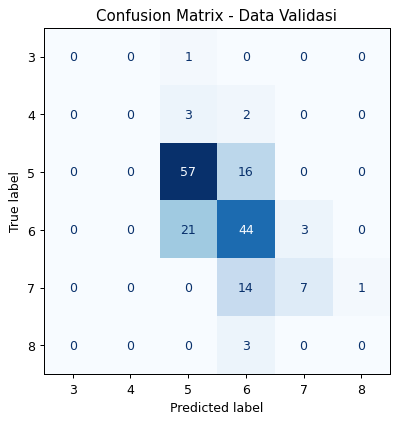

In [ ]:
fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred_val, labels=sorted(y.unique())),
                       display_labels=sorted(y.unique())).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix - Data Validasi'); plt.show()

**Interpretasi:** Akurasi data latih 100% sedangkan akurasi validasi sekitar 63%, menandakan model cenderung *overfit* ringan, hal yang umum pada ensemble pohon. Confusion matrix menunjukkan prediksi paling akurat pada kelas 5 dan 6 (kelas mayoritas). Kelas langka (3, 4, 8) hampir tidak pernah ditebak benar karena contohnya sangat sedikit. Kesalahan umumnya hanya berselisih satu tingkat, yang wajar untuk skor kualitas ordinal.

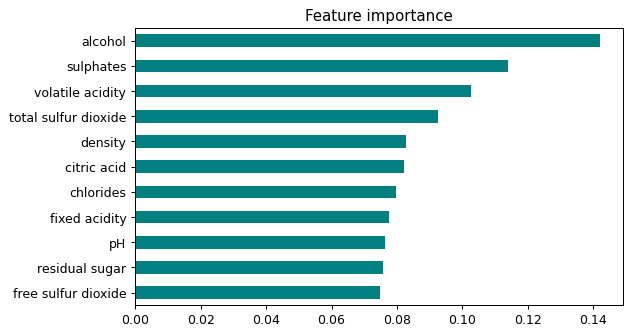

In [ ]:
imp = pd.Series(model.feature_importances_, index=features).sort_values()
imp.plot.barh(color='teal', figsize=(7,4)); plt.title('Feature importance'); plt.show()

**Interpretasi:** `alcohol`, `sulphates`, dan `volatile acidity` adalah fitur paling berpengaruh, konsisten dengan hasil korelasi sebelumnya.

### Melatih ulang pada seluruh data training & menyimpan model
Setelah evaluasi, model dilatih ulang menggunakan **seluruh** data training agar memanfaatkan semua informasi, lalu disimpan untuk deployment.

In [ ]:
final_model = ExtraTreesClassifier(n_estimators=500, random_state=SEED)
final_model.fit(X, y)
joblib.dump(final_model, O+'model_wine_extratrees.joblib')
print('Model tersimpan: model_wine_extratrees.joblib')
print('Akurasi pada seluruh data training:', round(accuracy_score(y, final_model.predict(X)),4))

Model tersimpan: model_wine_extratrees.joblib
Akurasi pada seluruh data training: 1.0


## 4. Prediksi Data Uji (Deployment)
Model yang tersimpan dimuat kembali dan digunakan memprediksi `data_test`. Hasil disimpan sesuai format template (`Id;Quality`).

In [ ]:
loaded = joblib.load(O+'model_wine_extratrees.joblib')
pred_test = loaded.predict(test[features])

hasil_df = pd.DataFrame({'Id': test['Id'], 'Quality': pred_test.astype(int)})
hasil_df.to_csv(O+'hasilprediksi_029_BP.csv', sep=';', index=False)

cek = pd.read_csv(O+'hasilprediksi_029_BP.csv', sep=';')
print('Kolom        :', list(cek.columns))
print('Jumlah baris :', len(cek), '(harus 286)')
print('Id sama dgn template:', set(cek.Id)==set(templ.Id), '| urutan sama:', (cek.Id.values==templ.Id.values).all())
print('Missing      :', cek.isna().sum().sum())
print('\nDistribusi prediksi:'); print(cek.Quality.value_counts().sort_index())
cek.head()

Kolom        : ['Id', 'Quality']
Jumlah baris : 286 (harus 286)
Id sama dgn template: True | urutan sama: True
Missing      : 0

Distribusi prediksi:
Quality
5    130
6    126
7     30
Name: count, dtype: int64


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,5


**Interpretasi:** File hasil hanya memuat dua kolom (`Id` dan `Quality`), jumlah baris dan urutan `Id` sama dengan template, serta tanpa nilai kosong. Distribusi prediksi mengikuti pola data training (didominasi kelas 5 dan 6).

## 5. Kesimpulan
- Data bersih (tanpa missing value); fitur memiliki skala beragam sehingga *scaling* diterapkan pada model yang sensitif skala.
- Dari 6 algoritma yang dibandingkan, **Extra Trees** memberi akurasi CV terbaik dan dipakai sebagai model final.
- Keterbatasan: kelas tidak seimbang membuat kelas minoritas (3, 4, 8) sulit diprediksi.
